# Self Organising Maps

Using self-organising maps to visualise the feature space

In [1]:
import sys

In [2]:
%matplotlib inline
sys.path.append("..")
import wavelet_transform.utils.training_data as train
import wavelet_transform.postprocess.plotting as plot

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
# Set sampling rate and noise std
sampling_rate = 50e6
std_noise = 0.05

# Set length of data to keep
sample_time = 20 / 1.5e6
data_len = int(sample_time * sampling_rate)

# Parameters for the wavelet transform
wavelet = "db10"
levels = 10  # max level for the transform
mode = "symmetric"
use_min_entropy = True
min_level = 3


### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.


In [4]:
wpt_df = train.generate_training_data_with_wavelet(wavelet, sampling_rate, levels, mode, std_noise, 
                                                   data_len, 
                                                   min_entropy=use_min_entropy, min_level=1
)

### Training

Train algorithm on the generated data

In [5]:
n_data_points = wpt_df.shape[0]
print("data points", n_data_points)
n_neurons = 5 * n_data_points ** (1 / 2)
print("neurons", n_neurons)

data points 609
neurons 123.38962679253066


### Feature selection

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn_som.som import SOM

# Get data, select which features to analyse
classifying_metrics = [
    # "centre frequency",
    "level",
    # "energy",
    "average energy",
    # "log energy",
    "log average energy",
    "crest factor",
    "abs skewness",
    "kurtosis",
    "entropy",
    "spectral entropy",
    "level entropy",
]
n_metrics = len(classifying_metrics)
data_train = wpt_df[classifying_metrics]

# Standardise data
scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# Self organising maps
som_rows = int(np.sqrt(n_neurons))  # make a square map
som_size = (som_rows, int(n_neurons / som_rows))  # set size
som_width, som_height = som_size
n_clusters = som_width * som_height
som = SOM(som_width, som_height, n_metrics, max_iter=100000)
labels = som.fit_predict(data_train_normalised, epochs=50)
print("itertations", som.n_iter_)

# Cluster centres
centers = som.cluster_centers_
# display(centers)
centers = som.cluster_centers_.reshape((n_clusters, n_metrics))
# print(centers)
centers = scaler.inverse_transform(centers)

# print("centers:", centers)

itertations 30450


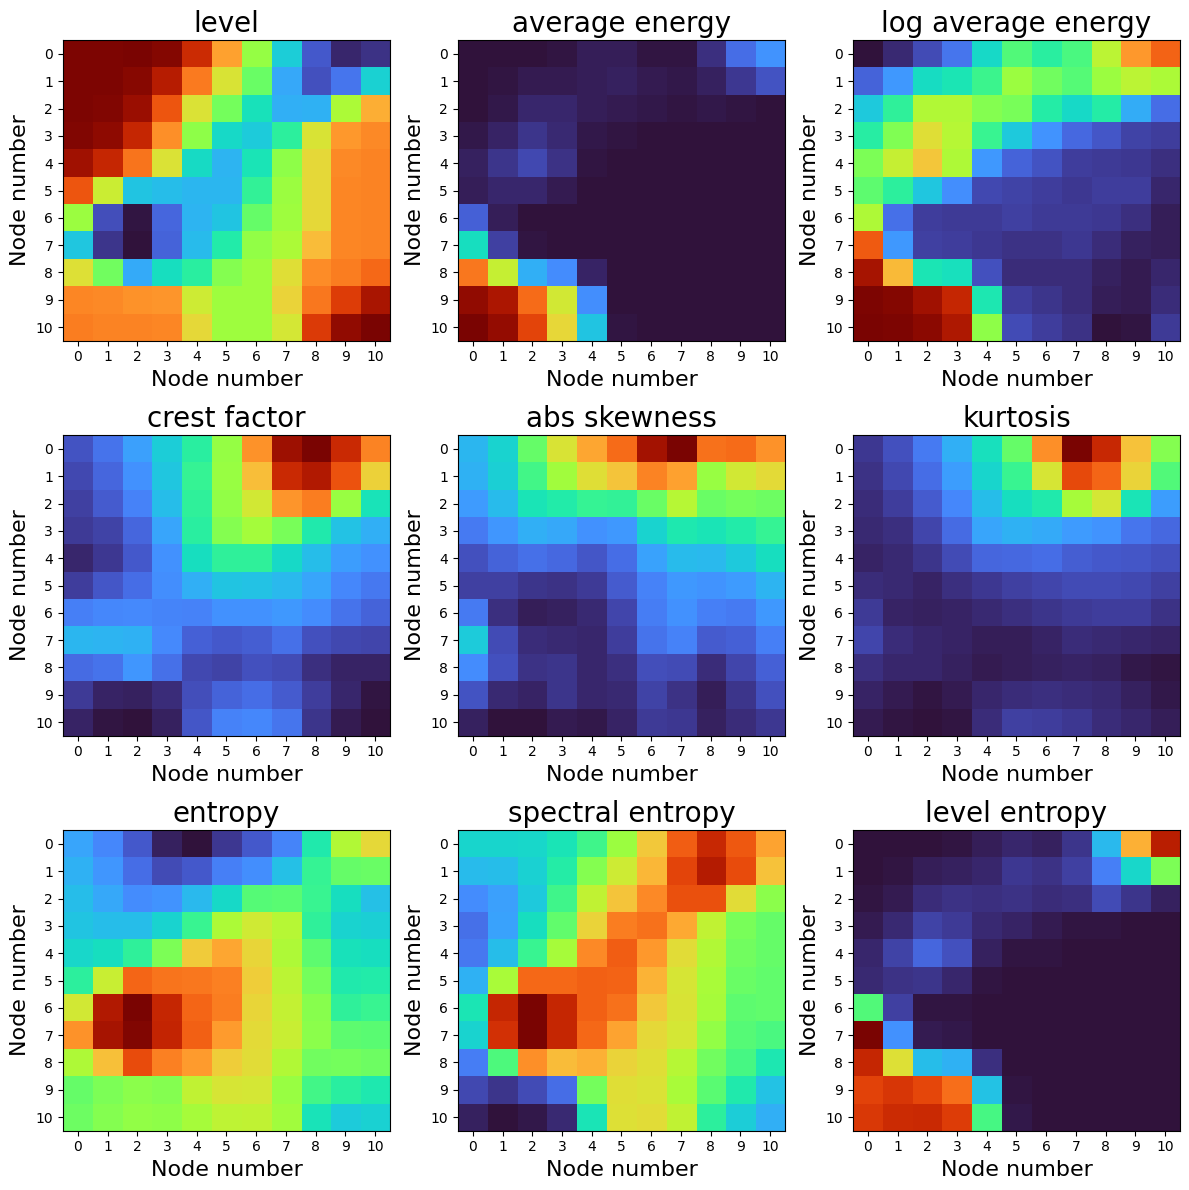

In [11]:
# Plotting heatmaps for each feature
columns = 3
rows = n_metrics / columns
if rows.is_integer() is False:
    rows = int(rows) + 1# round up if there aren't enough rows
rows = max(2, rows)
fig, axes = plt.subplots(int(rows), columns, figsize=(12, 12))

for i, feature in enumerate(classifying_metrics):
    row, col = i // columns, i % columns
    feature_values = centers[:, i].reshape(som_size[::-1])
    # print(centers[:, i])
    ax:plt.Axes = axes[row, col]
    ax.imshow(feature_values, cmap='turbo', aspect='auto')
    ax.set_title(f'{feature}', fontsize=20)
    ax.set_xlabel("Node number", fontsize=16)
    ax.set_ylabel("Node number", fontsize=16)
    ax.set_xticks(range(som_width))
    ax.set_yticks(range(som_height))

plt.tight_layout()
plt.show()